In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, make_scorer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [24]:
df = pd.read_csv("../data/german-credit-risk/german.data", sep=' ', header=None)
print(df)

      0   1    2    3     4    5    6   7    8     9   ...    11  12    13  \
0    A11   6  A34  A43  1169  A65  A75   4  A93  A101  ...  A121  67  A143   
1    A12  48  A32  A43  5951  A61  A73   2  A92  A101  ...  A121  22  A143   
2    A14  12  A34  A46  2096  A61  A74   2  A93  A101  ...  A121  49  A143   
3    A11  42  A32  A42  7882  A61  A74   2  A93  A103  ...  A122  45  A143   
4    A11  24  A33  A40  4870  A61  A73   3  A93  A101  ...  A124  53  A143   
..   ...  ..  ...  ...   ...  ...  ...  ..  ...   ...  ...   ...  ..   ...   
995  A14  12  A32  A42  1736  A61  A74   3  A92  A101  ...  A121  31  A143   
996  A11  30  A32  A41  3857  A61  A73   4  A91  A101  ...  A122  40  A143   
997  A14  12  A32  A43   804  A61  A75   4  A93  A101  ...  A123  38  A143   
998  A11  45  A32  A43  1845  A61  A73   4  A93  A101  ...  A124  23  A143   
999  A12  45  A34  A41  4576  A62  A71   3  A93  A101  ...  A123  27  A143   

       14 15    16 17    18    19 20  
0    A152  2  A173  1  A

In [25]:
column_names = [
    "checking_account_status",
    "duration_months",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment_since",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "target",
]
named_df = df.set_axis(column_names, axis=1)

In [26]:
named_df["target"].value_counts(normalize=True)

target
1    0.7
2    0.3
Name: proportion, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

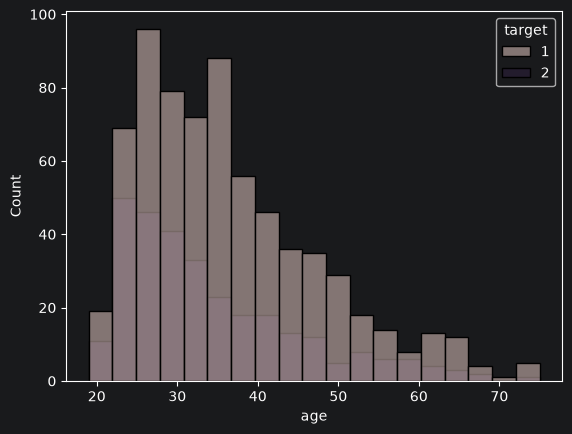

In [27]:
sns.histplot(data=named_df, x="age", hue="target")

<Axes: xlabel='duration_months', ylabel='Count'>

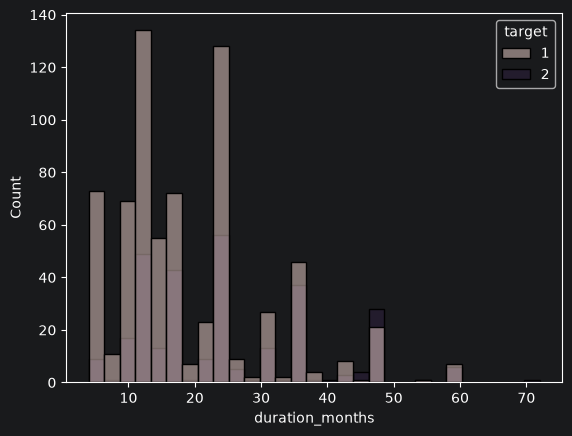

In [28]:
sns.histplot(data=named_df, x="duration_months", hue="target")

<Axes: xlabel='credit_amount', ylabel='Count'>

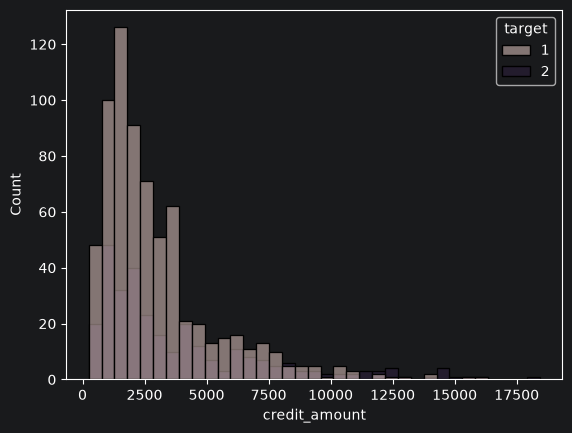

In [29]:
sns.histplot(data=named_df, x="credit_amount", hue="target")

<Axes: xlabel='target', ylabel='credit_amount'>

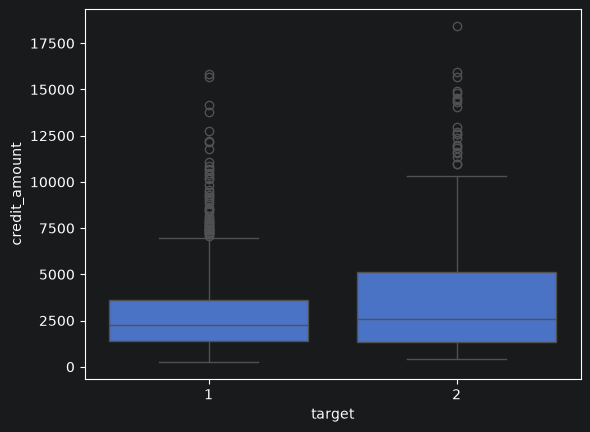

In [30]:
sns.boxplot(data=named_df, x="target", y="credit_amount")

In [31]:
feature_cols = ["duration_months", "credit_history", "purpose", "credit_amount", "age", "other_installment_plans", "people_liable", "job", "foreign_worker", "installment_rate", "employment_since", "checking_account_status", "housing", "existing_credits"]
X = named_df[feature_cols]
y = named_df["target"]

In [32]:
cat_cols = X.select_dtypes(include="str").columns
num_cols = X.select_dtypes(include="number").columns
print(cat_cols)
print(num_cols)

Index(['credit_history', 'purpose', 'other_installment_plans', 'job',
       'foreign_worker', 'employment_since', 'checking_account_status',
       'housing'],
      dtype='str')
Index(['duration_months', 'credit_amount', 'age', 'people_liable',
       'installment_rate', 'existing_credits'],
      dtype='str')


In [33]:
# find out which categories of each column can differentiate better the target outcome
# rather than finding out which columns do it better
class WoEEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, smoothing=0.5):
        self.smoothing = smoothing

    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = pd.Series(np.asarray(y), index=X.index)
        self.classes_ = np.sort(y.unique())
        good_label, bad_label = self.classes_ # lower label = good, higher = bad
        self.columns_ = X.columns.tolist()
        self.mappings_ = {}
        for col in self.columns_:
            counts = pd.crosstab(X[col], y)
            good = counts[good_label] + self.smoothing
            bad = counts[bad_label] + self.smoothing
            self.mappings_[col] = np.log((good / good.sum()) / (bad / bad.sum())) # more than one value for each column that has more than one category
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        out = pd.DataFrame(index=X.index)
        for col in self.columns_:
            out[col] = X[col].map(self.mappings_[col]).fillna(0.0)
        return out.to_numpy()


# find out which columns differentiate better the target output
class InformationValue:
    def __init__(self, smoothing=0.5):
        self.smoothing = smoothing

    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = pd.Series(np.asarray(y), index=X.index)
        good_label, bad_label = np.sort(y.unique())
        self.iv_ = {}
        for col in X.columns:
            counts = pd.crosstab(X[col], y)
            good = counts[good_label] + self.smoothing
            bad = counts[bad_label] + self.smoothing
            good_dist, bad_dist = good / good.sum(), bad / bad.sum()
            self.iv_[col] = ((good_dist - bad_dist) * np.log(good_dist / bad_dist)).sum()
        return self

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# preprocessor = ColumnTransformer([
#     ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
#     ("num", StandardScaler(), num_cols),
# ])

model = LogisticRegression(random_state=42)

preprocessor = ColumnTransformer([
    ("cat", WoEEncoder(), cat_cols),
    ("num", StandardScaler(), num_cols),
])

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

# X_train_t = preprocessor.fit_transform(X_train) # fit one hot encoder and apply transform
# X_test_t = preprocessor.transform(X_test)

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cvp = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['duration_months','credit_history','purpose',..., 'checking_account_status','housing','existing_credits']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [36]:
y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)[:, 1]

threshold = 0.139
comparison_pred = y_prob > threshold

threshold_p = np.where(comparison_pred, 2, 1)

In [37]:
binned = X_train[num_cols].apply(lambda s: pd.qcut(s, q=5, duplicates="drop"))
iv = InformationValue().fit(pd.concat([X_train[cat_cols], binned], axis=1), y_train)
pd.Series(iv.iv_).sort_values(ascending=False)

checking_account_status    0.609259
credit_history             0.262438
duration_months            0.213244
purpose                    0.149895
employment_since           0.124165
other_installment_plans    0.091050
housing                    0.088710
credit_amount              0.065430
foreign_worker             0.046790
age                        0.042884
installment_rate           0.030933
job                        0.012296
existing_credits           0.001245
people_liable              0.000000
dtype: float64

In [38]:
thresholds = np.linspace(0.05, 0.95, 91)
results = []
for t in thresholds:
    comparison_pred = cvp > t
    tp = np.where(comparison_pred, 2, 1)
    acc = accuracy_score(y_train, tp)
    conf_matrix = confusion_matrix(y_train, tp)
    cost = conf_matrix[1, 0] * 5 + conf_matrix[0, 1]
    results.append((acc, cost, t))

graph_df = pd.DataFrame(results, columns=["Accuracy", "Cost", "Threshold"])

0.4599999999999999
0.10999999999999999
0.74125
396


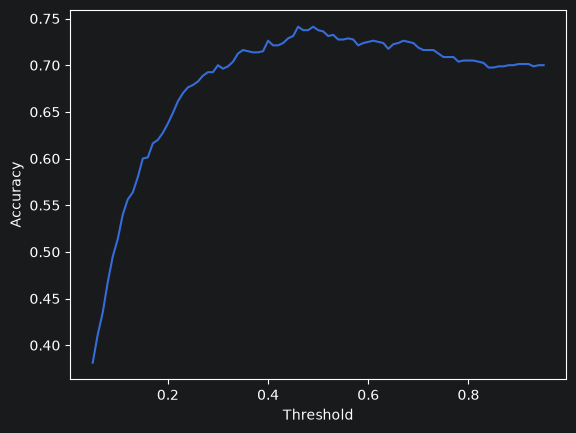

In [39]:
sns.lineplot(data=graph_df, y="Accuracy", x="Threshold")
print(graph_df.loc[graph_df["Accuracy"].idxmax()]["Threshold"])
print(graph_df.loc[graph_df["Cost"].idxmin()]["Threshold"])

print(graph_df["Accuracy"].max())
print(graph_df["Cost"].min())

<Axes: xlabel='Cost', ylabel='Threshold'>

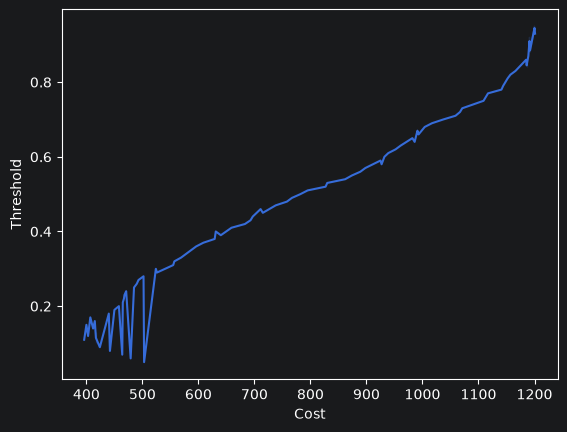

In [40]:
sns.lineplot(data=graph_df, x="Cost", y="Threshold")

In [41]:
print("Accuracy: ", accuracy_score(y_test, threshold_p))
confusion_matrix(y_test, threshold_p)

Accuracy:  0.55


array([[55, 85],
       [ 5, 55]])

In [42]:
classification_report(y_test, threshold_p)

'              precision    recall  f1-score   support\n\n           1       0.92      0.39      0.55       140\n           2       0.39      0.92      0.55        60\n\n    accuracy                           0.55       200\n   macro avg       0.65      0.65      0.55       200\nweighted avg       0.76      0.55      0.55       200\n'